In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression as sklearn_LinearRegressor

In [2]:
import sys
from pathlib import Path

# print(sys.path)

# Add the parent directory to Python's module search path
sys.path.append(str(Path.cwd().parent))

In [3]:
from LinearModels import LinearRegression as LinearRegressor

### Data

Its's data of 442 patients, for each patient we have corresponding measure for 10 features Then followed by Diabetes level.

In [4]:
X, y = load_diabetes(return_X_y=True)

In [5]:
y = y.reshape(-1, 1)

In [6]:
print(X.shape, y.shape)

(442, 10) (442, 1)


## Normalization

One of the advantages of performing normalization of the data is:
> **Most of the time, normalization makes the loss surface to have good conditioned number for Hessian, Geometrically it means The Curvature in all directions is better compared with loss surface of Unnormalized data**

> The advantage of having Identical curvature in all directions is, we can take a big steps during the learning process, that is our learning rate is much faster compared with LR of unnormalized data.

In the above image,

To the left: Loss surface of **MSE** of Unnormalized data, they are ellipses with $$\text{Length of Major Axis} >> \text{Length of Minor axis}$$
This is what makes the learning rate much slower.

To the right: Loss surface of **MSE** of Min-Max normalized data, We can clearly see that: $$\text{Length of Major Axis} \approx \text{Length of Minor axis}$$
This makes surface to the identical curvature in all directions, so the learning rate will be faster.

In [7]:
def min_max_normzlization(X):
    min_X = X.min(axis=0)
    max_X = X.max(axis=0)
    return (X-min_X)/(max_X-min_X)

def standardization(X):
    return (X-X.mean(axis=0))/X.std(axis=0)

In [8]:
X_norm = min_max_normzlization(X)
Y_norm = min_max_normzlization(y)

In [9]:
print(X.shape, y.shape, X_norm.shape, Y_norm.shape)

(442, 10) (442, 1) (442, 10) (442, 1)


In [10]:
X_train, X_val, y_train, y_val = train_test_split(X_norm, Y_norm, test_size=0.2, random_state=4)

In [11]:
print(X_train.shape, X_val.shape)

(353, 10) (89, 10)


# Model Comparisions

## Import the models

In [12]:
model = LinearRegressor(loss_func='mse')

In [13]:
model.compute_loss(X_train, y_train)

np.float64(1.4395612943003693)

In [14]:
sklearn_model = sklearn_LinearRegressor()

## Fit the models

In [15]:
sklearn_model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1, 10)","[[ 0.02,-0.09, 0.39,..., 0.23, 0.65, 0.03]]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.","ndarray[float64](1,)",[-0.15]
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,10
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(10)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](10,)","[9.76,6.13,3.97,...,2.38,0.9 ,0.29]"


In [16]:
loss_hist = model.learn(X_train, y_train, alpha=0.1, epochs=2_00_000)

In [17]:
print(f'Model Coefficients:\n{model.w.reshape((-1,))}\nSklearn Coefficients:\n{sklearn_model.coef_}\nIntercept:{model.b}\nSklearn Intercept:{sklearn_model.intercept_}')

Model Coefficients:
[ 0.02273515 -0.08676369  0.39100481  0.28100325 -0.83796559  0.57149867
  0.20214357  0.23401088  0.64696829  0.03215909]
Sklearn Coefficients:
[[ 0.02268438 -0.08678174  0.39090453  0.28103809 -0.84499034  0.5776469
   0.2054155   0.23499467  0.64939701  0.03220376]]
Intercept:-0.14542193552384505
Sklearn Intercept:[-0.14711803]


It appears even with more training our model co-efficients will get closer and closer the co-efficients given by `sklearn.LinearRegression`. The questions are:
>**Is it good to train the model for more and more number of epochs?**

> **Does it help the model to recognize the patterns that more generalizable to unseen data?**

## Validation Loss VS Training Loss

In [18]:
def plot_loss(X_train, y_train, X_val, y_val):
    m, n = X.shape
    w = np.ones((n, 1))
    b = 1
    train_max = X_train.max(axis=0)
    train_min = X_train.min(axis=0)

    target_max = y_val.max()
    target_min = y_val.min()

    train_loss = []
    val_loss = []
    model = LinearRegressor(w = w, b =b, loss_func='mse')
    epochs = 0
    i = 0
    while(i!=80):
        epochs += 50
        model.learn(X_train, y_train, alpha=0.1, epochs = epochs)

        train_loss.append(
            model.compute_loss(X_train, y_train)
        )

        val_loss.append(
            model.compute_loss(
                (X_val-train_min)/(train_max - train_min), (y_val - target_min)/(target_max - target_min)
            )
        )
        i +=1
    epochs = np.arange(1,81)*50
    fig, ax = plt.subplots(figsize=(10, 6))
    ax.plot(epochs, train_loss, label='Train Loss')
    ax.plot(epochs, val_loss, label='Validation Loss')
    ax.set_xlabel('Epochs')
    ax.set_ylabel('Loss')
    ax.set_title('Loss vs Epochs')

    max_loss = max(max(val_loss), max(train_loss))
    ax.set_ylim(0, max_loss)
    ax.set_xlim(0, 4000)
    
    
    ax.fill_between(np.arange(0, 601, 50), y1=0, y2=max_loss, 
                    color='#EDBEE6', alpha=0.5, label='UnderFit')
    ax.fill_between(np.arange(600, 1001, 100), y1=0, y2=max_loss,
                   color='#E8E8A7', alpha=0.5, label='Optimal')
    ax.fill_between(np.arange(1000, 4001, 500), y1=0, y2=max_loss, 
                    color='#CBF6D8', alpha=0.5, label='OverFit')
    ax.vlines(x=[600, 1000], ymax=0.0350, ymin=0, linestyles='--')

    ax.legend(fontsize='large')

    # fig.savefig('LinearReg_underfit_overfit.jpg', dpi=1200)


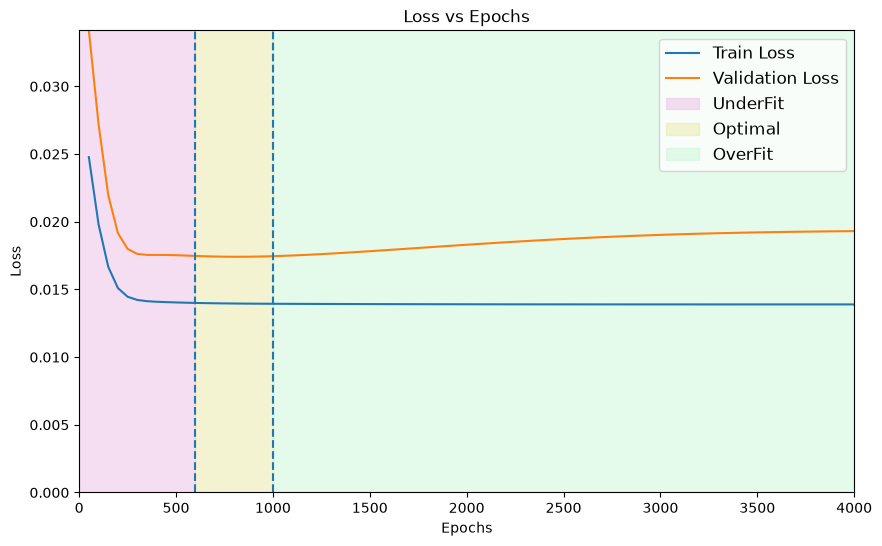

In [19]:
plot_loss(X_train, y_train, X_val, y_val)

> From the above picture, with such intialization as we train the model for more and more number of epochs, it isn't helping the model the recognize the **pattern that more generalizable to unseen data**, it's just recoginizing the patterns that are true for the training data. That's as we increase more and more number of epochs the validation loss keeps increasing and training loss keeps decreasing.

> We started with $w$ as vector of all ones and $b=1$, Then above picture releaves that: As we move beyond $1000$ epochs mark, we slowly moves into overfit region. So the optimal number of epochs is in between 600 and 1000.

## Learning

In [20]:
m, n = X.shape
w = np.ones((n, 1))
b = 1

In [21]:
final_model = LinearRegressor(w=w, b=b, loss_func='mse')

In [22]:
loss = final_model.learn(X_train, y_train, epochs=1000, alpha=0.1)

In [23]:
train_max = X_train.max(axis=0)
train_min = X_train.min(axis=0)

target_max = y_train.max()
target_min = y_train.min()

In [24]:
# let's compute the total loss on overall data set.
final_model.compute_loss(
    (X-train_min)/(train_max-train_min), (y-target_min)/(target_max-target_min)
)

np.float64(15021.583829317131)

In [25]:
print(f'Final Parameters:\n w:\n{final_model.w}\nb:{final_model.b}')

Final Parameters:
 w:
[[ 0.02519103]
 [-0.07801457]
 [ 0.44583283]
 [ 0.27992013]
 [-0.3002348 ]
 [-0.01414826]
 [ 0.20061167]
 [ 0.42044581]
 [ 0.37740486]
 [ 0.07023481]]
b:-0.14053761719044816
